# Analysis of all TS toegether

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize

FMS = ["Chronos-2-full", "TimesFM-2.5", "TiRex", "FlowState"]
SETS = {"Volatilität": ("binance_1h_neu", "qlike"),
        "Volatilität BTC/ETH/SOL": ("binance_1h", "qlike"),
        "Strom": ("strom_1h", "ape")}
EVAL_START, EVAL_END = "2025-11-01", "2026-03-01"


def loss(kind, y, f):
    r = y / f
    return r - np.log(r) - 1 if kind == "qlike" else np.abs(y - f) / y


rows = []
for domain, (ds, kind) in SETS.items():
    files = [p for p in (Path("results/forecasts") / ds).glob("*__*.parquet") if p.stem.split("__")[1] in FMS]
    if not files:
        print("fehlt:", ds); continue
    fc = pd.concat([pd.read_parquet(p) for p in files])
    fc = fc[(fc["target_date"] >= EVAL_START) & (fc["target_date"] < EVAL_END)]
    for (sid, h), g in fc.groupby(["sid", "h"]):
        M = g.pivot_table(index="origin", columns="model", values="mean").dropna()
        y = g.groupby("origin")["y"].first().reindex(M.index).to_numpy()
        F = M.to_numpy()
        C = np.corrcoef(np.log(y[:, None] / F).T)
        best = loss(kind, y[:, None], F).mean(0).min()
        obj = lambda z: loss(kind, y, F @ (np.exp(z) / np.exp(z).sum())).mean()
        z = minimize(obj, np.zeros(F.shape[1]), method="Nelder-Mead", options={"maxiter": 4000}).x
        rows.append({"Domäne": domain, "Serie": sid, "h": h, "FMs": F.shape[1],
                     "Korrelation": C[np.triu_indices_from(C, 1)].mean(),
                     "Verbesserung %": -100 * (obj(z) / best - 1)})

pts = pd.DataFrame(rows)
display(pts.round(3))
print("Rangkorrelation Korrelation vs. Verbesserung:", round(pts["Korrelation"].corr(pts["Verbesserung %"], method="spearman"), 2))

,Domäne,Serie,h,FMs,Korrelation,Verbesserung %
0,Volatilität,BNBUSDT,1,4,0.974,0.507
1,Volatilität,BNBUSDT,24,4,0.933,0.922
2,Volatilität,EURUSDT,1,4,0.976,0.486
3,Volatilität,EURUSDT,24,4,0.975,0.703
4,Volatilität,PAXGUSDT,1,4,0.961,1.160
5,Volatilität,PAXGUSDT,24,4,0.944,0.000
6,Volatilität,XRPUSDT,1,4,0.969,0.555
7,Volatilität,XRPUSDT,24,4,0.954,1.741
8,Volatilität BTC/ETH/SOL,BTCUSDT,1,2,0.964,0.230
9,Volatilität BTC/ETH/SOL,BTCUSDT,24,2,0.949,0.966


Rangkorrelation Korrelation vs. Verbesserung: -0.76


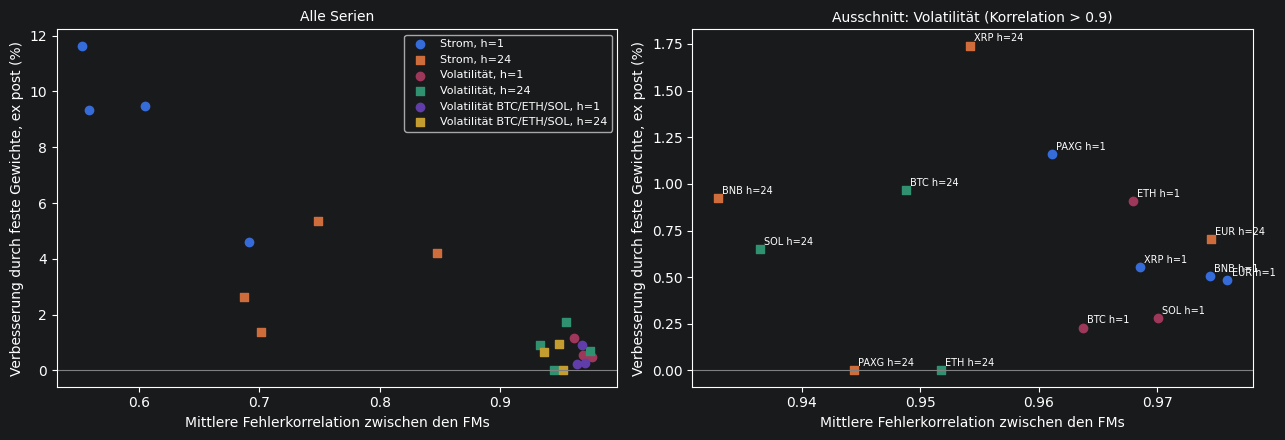

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
zoom = pts[pts["Korrelation"] > 0.9]

for ax, data in [(ax1, pts), (ax2, zoom)]:
    for (dom, h), d in data.groupby(["Domäne", "h"]):
        ax.scatter(d["Korrelation"], d["Verbesserung %"], marker="o" if h == 1 else "s", label=f"{dom}, h={h}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("Mittlere Fehlerkorrelation zwischen den FMs")
    ax.set_ylabel("Verbesserung durch feste Gewichte, ex post (%)")

for _, r in zoom.iterrows():                       # Serien im Zoom beschriften
    ax2.annotate(f'{r["Serie"].replace("USDT", "")} h={r["h"]}', (r["Korrelation"], r["Verbesserung %"]),
                 fontsize=7, xytext=(3, 3), textcoords="offset points")

ax1.set_title("Alle Serien", fontsize=10)
ax2.set_title("Ausschnitt: Volatilität (Korrelation > 0.9)", fontsize=10)
ax1.legend(fontsize=8)
plt.tight_layout()
fig.savefig("results/korrelation_vs_gewinn.png", dpi=200)
plt.show()

The chart shows that combination of FMs is more useful the less correlation among the FMs.